# SAM3 마스크 경계 오버레이 검증 — 옷 한 번 세그먼트 + border vs bbox

### 이 노트북이 답하려는 질문
파츠별로 나눠서 탐지하는 방식(`../sam3-parts-segment-check/`)은 실측 결과가 나빠 폐기했다. 이 노트북은 **원래 계획대로 옷을 한 번만 세그먼트하고 그 안에서 곧바로 하자를 탐지**하는, 프로덕션과 같은 단계 수의 파이프라인만 쓴다. 여기서 남은 질문은 딱 하나 — **bbox 사각형 대신 마스크 윤곽선+반투명 채우기로 하자를 표시하면 실제로 더 나아 보이는가**.

### 실행 순서
0. 의존성 설치 -> HF 로그인 -> GPU 확인 -> 설정 -> 모델 로드 -> 테스트 이미지
1. Step 1 — 의류 탐지 + 시각화 (한 번만)
2. Step 2 — 그 크롭 안에서 하자 탐지 + 공통 후처리
3. Step 3 — 최종 비교: bbox vs border, 나란히
4. 이미지 전체 배치 실행 + 결과 표

**프로덕션(`app/`, `worker/`)은 건드리지 않는다.** 여기서 border 표현이 낫다고 판단되면 별도 계획 문서로 프로덕션 반영 여부를 결정한다.


## 0. 의존성 설치


In [ ]:
# sam3-condition-check 스파이크와 같은 의존성(torch/transformers/opencv)을 재사용한다.
%pip install -q -r "../sam3-condition-check/requirements-sam3.txt"


## 0-1. Hugging Face 로그인 (gated repo)


In [1]:
import os

from huggingface_hub import login

hf_token = os.getenv("HF_TOKEN")
if hf_token:
    login(token=hf_token)
    print("HF_TOKEN 환경변수로 로그인했습니다.")
else:
    print("HF_TOKEN이 없습니다 — huggingface-cli login을 미리 실행했다면 그대로 진행됩니다.")


c:\Users\SSAFY\miniforge3\envs\qual\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF_TOKEN 환경변수로 로그인했습니다.


## 0-2. CUDA / GPU 확인


In [2]:
import torch

print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device:", torch.cuda.get_device_name(0))


cuda available: True
device: NVIDIA GeForce RTX 4070 Laptop GPU


## 0-3. 경로·설정


In [3]:
import sys

# 공유 유틸(qc_shared.py)은 이 폴더의 부모(validation/QUAL/)에 있다.
sys.path.insert(0, "..")
# Sam3Caller/crop_and_mask_to/draw_bordered_findings는 새로 만들지 않고
# sam3-parts-segment-check/의 검증된 구현을 그대로 재사용한다(parts.py는 import하지 않는다).
sys.path.insert(0, "../sam3-parts-segment-check")

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

import qc_shared
from border_overlay import draw_bordered_findings
from sam3_caller import Sam3Caller, crop_and_mask_to

qc_shared.use_korean_font()  # 그래프 제목 한글이 두부(□□)로 깨지지 않게

# ── 실험용 변수 — 여기 값만 바꾸고 이 셀부터 재실행 ──────────────────────
GARMENT_CROP_PAD_RATIO = 0.05


## 0-4. 모델 로드 — `Sam3Caller`


In [4]:
caller = Sam3Caller()
caller._ensure_loaded()  # 로그·디바이스 확인용으로 미리 로드(첫 detect() 호출에서 자동으로도 됨)


[Sam3Caller] 로딩 중... (model=facebook/sam3, device=cuda)


Loading weights: 100%|██████████| 1468/1468 [00:00<00:00, 2678.03it/s]


[Sam3Caller] 로드 완료


## 0-5. 테스트 이미지 로드


이미지 12장: ['black_stain.png', 'black_washed.jpg', 'denim.jpg', 'fix.jpg', 'levis_patch.jpg', 'logo_test.jpg', 'navy_logo.png', 'navy_trucker.jpg', 'scratch.jpg', 'shirt_red.png', 'small_pro.jpg', 'vintage_t.png']


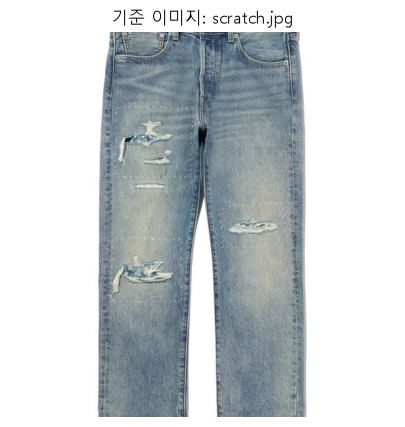

In [10]:
image_paths = qc_shared.list_images()
assert image_paths, "sample_images/ 에 이미지가 없습니다 (qc_shared.SHARED_IMAGE_DIR 참고)."
print(f"이미지 {len(image_paths)}장: {[p.name for p in image_paths]}")

# §1~§3은 이 기준 이미지 1장으로 단계별로 확인한다. §4에서 전체 배치를 돈다.
demo_path = image_paths[8]
demo_image = Image.open(demo_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(demo_image)
plt.title(f"기준 이미지: {demo_path.name}")
plt.axis("off")
plt.show()


## 1. Step 1 — 의류 탐지 + 시각화 (한 번만)

`GARMENT_PROMPT`("clothing")로 의류 인스턴스를 찾고, 가장 큰 것을 채택한다(`qc_shared.pick_largest`). 파츠 분할 없이 이 크롭 하나로 바로 하자 탐지로 넘어간다.


의류 후보 1건, 채택: True


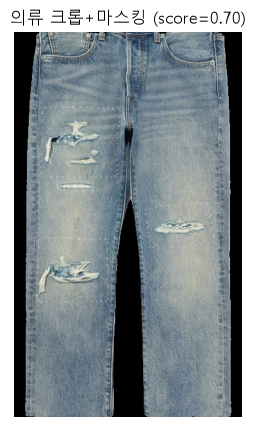

In [11]:
garment_threshold = qc_shared.BACKEND_THRESHOLDS["sam3"]["garment_score"]
ve_full = caller.vision_embeds(demo_image)
garment_instances = caller.detect(demo_image, "GARMENT", qc_shared.GARMENT_PROMPT, garment_threshold, ve_full)
garment = qc_shared.pick_largest(garment_instances)
print(f"의류 후보 {len(garment_instances)}건, 채택: {garment is not None}")

if garment is not None:
    garment_mask, garment_bbox = garment["mask"], garment["bbox"]
    garment_crop, garment_crop_box = crop_and_mask_to(demo_image, garment_bbox, garment_mask, GARMENT_CROP_PAD_RATIO)
    plt.figure(figsize=(5, 5))
    plt.imshow(garment_crop)
    plt.title(f"의류 크롭+마스킹 (score={garment['confidence']:.2f})")
    plt.axis("off")
    plt.show()
else:
    garment_mask, garment_crop, garment_crop_box = None, demo_image, None
    print("의류를 못 찾았습니다 — 원본 전체로 폴백합니다.")


## 2. Step 2 — 그 크롭 안에서 하자 탐지 + 공통 후처리

의류 겹침 필터 -> 양성 억제 -> cross-type dedup -> 번호매기기까지, 프로덕션(`worker/models/sam3/findings.py`)과 같은 후처리를 그대로 태운다.


In [12]:
defect_threshold = qc_shared.BACKEND_THRESHOLDS["sam3"]["score"]


def detect_defects_and_benigns(image):
    ve = caller.vision_embeds(image)
    defects = [
        inst
        for defect_type, prompt in qc_shared.DEFECT_PROMPTS.items()
        for inst in caller.detect(image, defect_type, prompt, defect_threshold, ve)
    ]
    benigns = [
        inst
        for benign_type, prompt in qc_shared.BENIGN_PROMPTS.items()
        for inst in caller.detect(image, benign_type, prompt, defect_threshold, ve)
    ]
    return defects, benigns


raw_defects, raw_benigns = detect_defects_and_benigns(garment_crop)
if garment_crop_box is not None:
    raw_defects = qc_shared.remap_instances_to_full(raw_defects, garment_crop_box, demo_image.size)
    raw_benigns = qc_shared.remap_instances_to_full(raw_benigns, garment_crop_box, demo_image.size)

kept, _dropped_off_garment = qc_shared.filter_by_garment(raw_defects, garment_mask)
kept, _dropped_benign = qc_shared.suppress_benign(kept, raw_benigns)
kept, _dropped_dupe = qc_shared.dedupe_cross_type(kept)
kept = qc_shared.renumber(kept)
print(f"최종 하자 {len(kept)}건")


최종 하자 6건


## 3. Step 3 — 최종 비교: bbox vs border

왼쪽은 기존 방식(사각형 bbox, `qc_shared.draw_numbered_boxes`), 오른쪽은 새 방식(마스크 윤곽선+반투명 채우기, `draw_bordered_findings`)이다. **같은 탐지 결과**를 표현 방식만 바꿔서 그린다.


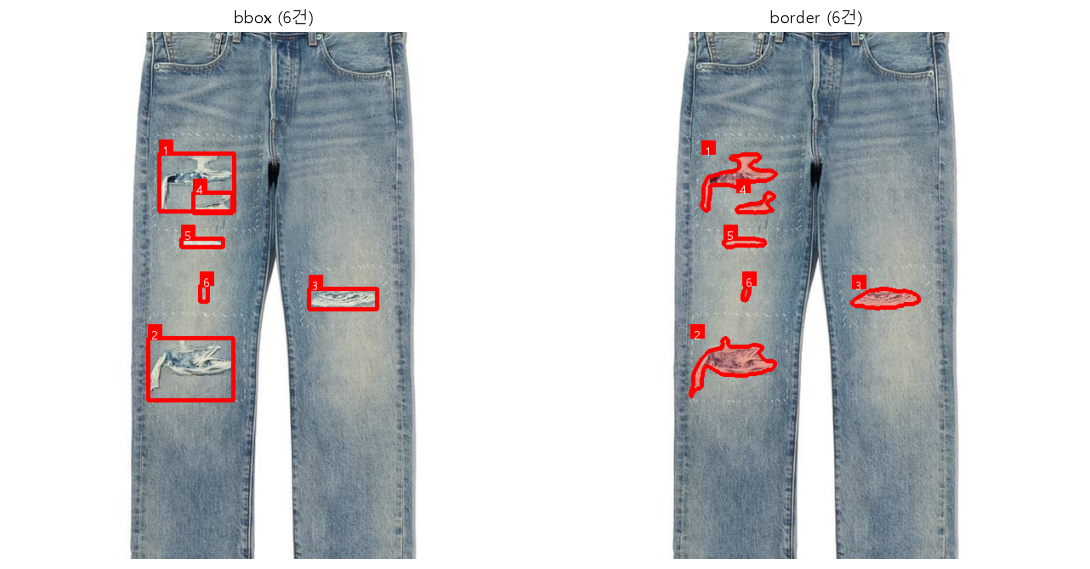

In [13]:
bbox_overlay = qc_shared.draw_numbered_boxes(demo_image, kept)
border_overlay = draw_bordered_findings(demo_image, kept, qc_shared.KOREAN_LABELS, qc_shared.korean_font_path)

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
axes[0].imshow(bbox_overlay)
axes[0].set_title(f"bbox ({len(kept)}건)")
axes[0].axis("off")
axes[1].imshow(border_overlay)
axes[1].set_title(f"border ({len(kept)}건)")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 4. 이미지 전체 배치 실행 + 결과 표

§1~§3을 이미지마다 반복해서 건수만 표로 모은다. 개별 이미지를 다시 자세히 보고 싶으면 `demo_path`/`demo_image`를 바꿔서 §1부터 재실행한다.


In [14]:
import pandas as pd

from border_overlay_check import run_one

rows = []
for path in image_paths:
    image = Image.open(path).convert("RGB")
    result = run_one(caller, image)
    rows.append({"image": path.name, "garment_found": result["garment_found"], "finding_count": len(result["kept"])})

summary_df = pd.DataFrame(rows)
summary_df


,image,garment_found,finding_count
0,black_stain.png,True,0
1,black_washed.jpg,True,0
2,denim.jpg,True,1
3,fix.jpg,True,7
4,levis_patch.jpg,True,5
5,logo_test.jpg,True,0
6,navy_logo.png,True,0
7,navy_trucker.jpg,True,0
8,scratch.jpg,True,6
9,shirt_red.png,True,0


## 결론 (실행 후 채울 것)

- border 오버레이가 bbox보다 실제로 더 보기 좋은가(불규칙한 하자 모양 표현):
- 채택할 만한가, 아니면 bbox가 더 낫거나 차이가 없는가:

### 후속 작업
- 채택한다면 `docs/plans/AI/`에 프로덕션 반영 설계 계획을 먼저 쓴다(CH006 선례). 여기 코드를 그대로 승격하지 않는다 — 프로덕션은 계획 문서 승인 후에만 손댄다.
